# Chapter 22 — Volatility Products: VIX, Variance Swaps, and Dispersion

The chapter's instruments, built from their definitions and made to reproduce the
chapter's numbers. **NumPy only** (matplotlib for the two plots). The variance strip,
the delta-hedged log contract, the Cboe calculation and the dispersion identity are
written out rather than called from a library, so the formula in the text and the
code are the same object.

| Section | What is built | Text |
|---|---|---|
| 1 | Black–Scholes–Merton prices and a `show` helper | — |
| 2 | The $1/K^2$ strip, and where its error comes from | Example 22.1, (22.5) |
| 3 | Variance against volatility | Example 22.2 |
| 4 | Delta-hedging a log contract against a straddle | §§22.1, 22.3 |
| 5 | The seller's convexity, and what a cap is worth | Example 22.3, March 2020 case study |
| 6 | VIX from a chain, step by step | Example 22.4, (22.6)–(22.8) |
| 7 | The roll | Example 22.5 |
| 8 | The inverse product's rebalance | Example 22.6, Figure 22.4 |
| 9 | Dispersion | Example 22.8, Figure 22.5 |
| 10 | Forward variance | Example 22.9 |

Every printed figure is shown beside the number the chapter prints, with `ok` when
they agree to the chapter's rounding.

## 1. Black–Scholes–Merton prices and a checking helper

Every price below is a Black–Scholes price on some volatility: a flat one, a skewed
one, or one that changes along a simulated path. `show` prints a computed value
beside the chapter's.

In [1]:
import numpy as np
from math import log, sqrt, exp, erf

N = np.vectorize(lambda x: 0.5 * (1.0 + erf(x / sqrt(2.0))))


def show(label, got, printed, tol=None):
    # tol defaults to half a unit in the last printed digit
    if tol is None:
        s = repr(float(printed)).split(".")
        tol = 0.5 * 10 ** -(len(s[1]) if len(s) > 1 else 0) + 1e-12
    flag = "ok" if abs(got - printed) <= tol else "DIFFERS"
    print("%-46s %14.7g   book %12.7g   %s" % (label, got, printed, flag))


def bs(S, K, T, r, q, sig, call=True):
    d1 = (log(S / K) + (r - q + 0.5 * sig * sig) * T) / (sig * sqrt(T))
    d2 = d1 - sig * sqrt(T)
    c = S * exp(-q * T) * float(N(d1)) - K * exp(-r * T) * float(N(d2))
    return c if call else c - S * exp(-q * T) + K * exp(-r * T)

## 2. The $1/K^2$ strip — Example 22.1

Equation (22.5) prices the fair variance swap rate as a strip of out-of-the-money
options weighted $\Delta K/K^2$. On a flat 20% surface the answer must be exactly 20%,
so any departure is the strip's own error. The table widens the range and, in its
last row, narrows the spacing.

In [2]:
S0, R, Q, T = 100.0, 0.02, 0.0, 1.0
F = S0 * exp((R - Q) * T)


def strip_vol(lo, hi, step, sig=0.20, offset=0.0):
    # (22.5) as a discrete sum: puts below the forward, calls above
    total, K = 0.0, lo + offset
    while K <= hi + 1e-9:
        total += step / K**2 * bs(S0, K, T, R, Q, sig, call=(K >= F))
        K += step
    return sqrt(2.0 * exp(R * T) / T * total)


print("forward %.2f" % F)
for lo, hi, step, book in ((50, 200, 5, 19.956), (30, 300, 5, 19.956),
                           (20, 500, 5, 19.956), (10, 800, 2, 20.015)):
    show("%d-%d, step %d (%%)" % (lo, hi, step), 100 * strip_vol(lo, hi, step), book)
show("a put struck at 50 is worth (cents)", 100 * bs(S0, 50, T, R, Q, 0.20, call=False), 0.06, tol=0.01)

forward 102.02
50-200, step 5 (%)                                   19.95606   book       19.956   ok
30-300, step 5 (%)                                    19.9564   book       19.956   ok
20-500, step 5 (%)                                    19.9564   book       19.956   ok
10-800, step 2 (%)                                   20.01506   book       20.015   ok
a put struck at 50 is worth (cents)                0.06263783   book         0.06   ok


The range does nothing at 20% volatility; the spacing does. The error depends on
where the grid meets the forward, 102.02, where the strip switches from puts to calls
and the out-of-the-money price has a kink. Slide the grid across the forward and the
error traces a full cycle; its size shrinks with the square of the spacing.

In [3]:
def grid_error_bp(step, offset, lo):
    return 1e4 * (strip_vol(lo, 1000.0, step, offset=offset) - 0.20)


offsets5 = np.linspace(0.0, 5.0, 51)
err5 = [grid_error_bp(5, o, 5.0) for o in offsets5]
show("book's 5-point grid (bp)", grid_error_bp(5, 0.0, 5.0), -4.4, tol=0.1)
show("5-point grid, strike on the forward (bp)", grid_error_bp(5, (F - 5) % 5, 5.0), 10.0, tol=0.1)
show("5-point grid, worst negative offset (bp)", min(err5), -5.0, tol=0.1)
show("2-point grid, strike at 102 (bp)", grid_error_bp(2, 0.0, 4.0), 1.5, tol=0.05)
show("2-point grid, strike on the forward (bp)", grid_error_bp(2, (F - 4) % 2, 4.0), 1.6, tol=0.05)

book's 5-point grid (bp)                            -4.359905   book         -4.4   ok
5-point grid, strike on the forward (bp)             9.976144   book           10   ok
5-point grid, worst negative offset (bp)            -5.007054   book           -5   ok
2-point grid, strike at 102 (bp)                     1.506042   book          1.5   ok
2-point grid, strike on the forward (bp)             1.600491   book          1.6   ok


At high volatility the ranking reverses: the options beyond 50 and 200 are worth
something, and truncation, not spacing, is the error.

In [4]:
for lo, hi, step in ((50, 200, 5), (30, 300, 5), (20, 500, 5), (10, 800, 2)):
    print("60%% volatility, %3d-%3d step %d: %6.2f%%" % (lo, hi, step, 100 * strip_vol(lo, hi, step, sig=0.60)))

60% volatility,  50-200 step 5:  56.99%
60% volatility,  30-300 step 5:  59.64%
60% volatility,  20-500 step 5:  59.96%
60% volatility,  10-800 step 2:  60.00%


## 3. Variance against volatility — Example 22.2

If realized volatility is lognormal with mean $\bar\sigma$ and log standard deviation
$\nu$, then $E[\sigma_R^2] = \bar\sigma^2 e^{\nu^2}$, so the variance swap strike
$\sqrt{E[\sigma_R^2]}$ exceeds the volatility swap strike $\bar\sigma$ by
$\bar\sigma(e^{\nu^2/2} - 1)$. A simulation checks the closed form.

In [5]:
rng = np.random.default_rng(22)
sbar = 20.0
for nu, book in ((0.20, 20.40), (0.30, 20.92), (0.50, 22.66), (0.70, 25.55)):
    closed = sbar * exp(nu * nu / 2)
    sims = sbar * np.exp(nu * rng.standard_normal(400_000) - nu * nu / 2)   # mean sbar
    show("nu %.0f%%: variance swap strike" % (100 * nu), closed, book)
    print("%-46s %13.4f" % ("    simulated sqrt(E[sigma^2])", sqrt(np.mean(sims**2))))
print("nu 40%%-60%%: spread %.2f to %.2f points" % (sbar * (exp(0.08) - 1), sbar * (exp(0.18) - 1)))

nu 20%: variance swap strike                         20.40403   book         20.4   ok
    simulated sqrt(E[sigma^2])                       20.4117
nu 30%: variance swap strike                         20.92056   book        20.92   ok
    simulated sqrt(E[sigma^2])                       20.9363
nu 50%: variance swap strike                         22.66297   book        22.66   ok
    simulated sqrt(E[sigma^2])                       22.6773
nu 70%: variance swap strike                         25.55243   book        25.55   ok
    simulated sqrt(E[sigma^2])                       25.6111
nu 40%-60%: spread 1.67 to 3.94 points


## 4. Delta-hedging a log contract, and a straddle

Section 22.3's claim is that a delta-hedged log contract earns realized variance on
*every* path, while §22.1's delta-hedged straddle earns it weighted by gamma, so two
paths with the same realized variance pay differently.

The simulation draws paths whose volatility itself varies, so realized variance
differs from path to path. On each, it runs the log contract's hedge (the
identity $\sum 2(\Delta S/S) - 2\ln(S_T/S_0)$, one rebalance a day) and a straddle
bought at 20% implied and delta-hedged daily at that volatility. Plotted against each
path's realized variance, the first lies on a line; the second scatters.

In [6]:
rng = np.random.default_rng(7)
n_paths, n_days, T1 = 2000, 252, 1.0
dt = T1 / n_days
sig_path = 0.20 * np.exp(0.35 * rng.standard_normal((n_paths, 1)))           # each path's level
sig_t = sig_path * np.exp(0.25 * np.cumsum(rng.standard_normal((n_paths, n_days)), axis=1) / sqrt(n_days))
z = rng.standard_normal((n_paths, n_days))
logret = -0.5 * sig_t**2 * dt + sig_t * sqrt(dt) * z                           # r = q = 0
S = 100.0 * np.exp(np.cumsum(logret, axis=1))
S = np.hstack([np.full((n_paths, 1), 100.0), S])

realized = (252.0 / n_days) * np.sum(logret**2, axis=1)                     # (22.3)
simple = S[:, 1:] / S[:, :-1] - 1.0
log_contract = 2.0 * np.sum(simple, axis=1) - 2.0 * np.log(S[:, -1] / S[:, 0])   # (22.4), per year

K, IV = 100.0, 0.20


def straddle_delta(s, tau):
    d1 = (np.log(s / K) + 0.5 * IV * IV * tau) / (IV * np.sqrt(tau))
    return 2.0 * N(d1) - 1.0


premium = bs(100.0, K, T1, 0.0, 0.0, IV) + bs(100.0, K, T1, 0.0, 0.0, IV, call=False)
hedge = np.zeros(n_paths)
for i in range(n_days):
    tau = T1 - i * dt
    hedge -= straddle_delta(S[:, i], tau) * (S[:, i + 1] - S[:, i])
straddle = np.abs(S[:, -1] - K) - premium + hedge

c_log = np.corrcoef(realized, log_contract)[0, 1]
c_str = np.corrcoef(realized - IV**2, straddle)[0, 1]
print("correlation with realized variance, log contract : %.4f" % c_log)
print("correlation with realized variance, straddle     : %.4f" % c_str)
print("log contract minus realized variance, s.d.       : %.6f" % np.std(log_contract - realized))

correlation with realized variance, log contract : 1.0000
correlation with realized variance, straddle     : 0.8599
log contract minus realized variance, s.d.       : 0.000135


The log contract's residual is the discretization of daily hedging (the
$2(e^x-1-x) - x^2 \approx x^3/3$ term of §22.10), and it is small. The straddle's
scatter is the gamma weighting: a path that drifted away from the strike earned little
of its variance.

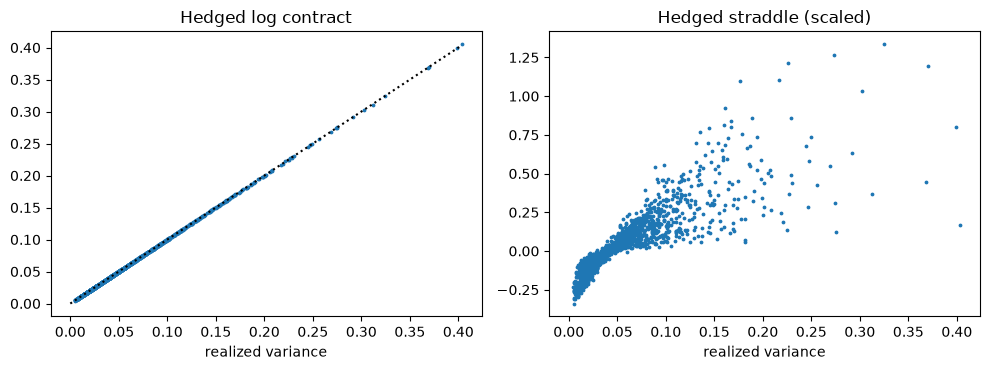

In [7]:
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
    ax[0].scatter(realized, log_contract, s=3)
    ax[0].plot([0, realized.max()], [0, realized.max()], "k:")
    ax[0].set_title("Hedged log contract")
    ax[1].scatter(realized, straddle / (100.0 * sqrt(T1) * 0.4), s=3)
    ax[1].set_title("Hedged straddle (scaled)")
    for a in ax:
        a.set_xlabel("realized variance")
    plt.tight_layout()
    plt.show()
except ImportError:
    print("matplotlib not installed; the correlations above carry the result")

## 5. The seller's convexity, and what a cap is worth — Example 22.3 and the March 2020 case study

A long variance swap with vega notional $N_{\text{vega}}$ pays
$N_{\text{vega}}(\sigma_R^2 - K_{\text{var}}^2)/(2K_{\text{var}})$, (22.2). The table
compares it with a contract linear in volatility; the case study then caps realized
volatility at 2.5 times the strike.

In [8]:
def var_payoff(realized_vol, strike, vega_notional):
    return vega_notional * (realized_vol**2 - strike**2) / (2.0 * strike)


for rv, book in ((10, -750_000), (15, -437_500), (25, 562_500), (30, 1_250_000), (40, 3_000_000)):
    show("struck at 20, realized %d: payoff ($)" % rv, var_payoff(rv, 20, 100_000), book, tol=1)
uncapped = var_payoff(80, 15, 100_000)
capped = var_payoff(min(80, 2.5 * 15), 15, 100_000)
show("March 2020, uncapped loss ($m)", uncapped / 1e6, 20.6, tol=0.05)
show("March 2020, capped at 2.5x ($m)", capped / 1e6, 3.9, tol=0.05)
show("the cap's factor", uncapped / capped, 5.2, tol=0.05)
show("Example 22.7: short at 18, realized 15 (points)", -var_payoff(15, 18, 1.0), 2.75, tol=0.005)

struck at 20, realized 10: payoff ($)                 -750000   book      -750000   ok
struck at 20, realized 15: payoff ($)                 -437500   book      -437500   ok
struck at 20, realized 25: payoff ($)                  562500   book       562500   ok
struck at 20, realized 30: payoff ($)                 1250000   book      1250000   ok
struck at 20, realized 40: payoff ($)                 3000000   book      3000000   ok
March 2020, uncapped loss ($m)                       20.58333   book         20.6   ok
March 2020, capped at 2.5x ($m)                        3.9375   book          3.9   ok
the cap's factor                                     5.227513   book          5.2   ok
Example 22.7: short at 18, realized 15 (points)           2.75   book         2.75   ok


## 6. VIX from a chain — Example 22.4

The surface is synthetic, defined here: an S&P at 4500, a skew of $0.17 - 0.55\ln(K/F)$,
priced off a forward that carries a 1.4% dividend yield the construction never sees.
The steps are the Cboe rule of §22.6: the forward from put–call parity at the strike
where call and put are closest; $K_0$, the highest listed strike at or below it;
out-of-the-money options walked outward until two consecutive strikes have no bid;
the sum (22.7) with its correction term; and the 30-day blend (22.8).

In [9]:
SPX, RV, QV, ATM, SKEW = 4500.0, 0.042, 0.014, 0.17, 0.55
TN, TX = 24.0 / 365.0, 31.0 / 365.0


def vix_price(K, T, Ftrue, call):
    sig = min(max(ATM - SKEW * log(K / Ftrue), 0.07), 1.20)
    s = sig * sqrt(T)
    d1 = (log(Ftrue / K) + 0.5 * s * s) / s
    d2, df = d1 - s, exp(-RV * T)
    nd = lambda x: 0.5 * (1.0 + erf(x / sqrt(2.0)))
    return df * (Ftrue * nd(d1) - K * nd(d2)) if call else df * (K * nd(-d2) - Ftrue * nd(-d1))


def vix_term(T, no_bid=0.05):
    Ftrue = SPX * exp((RV - QV) * T)
    grid = range(500, 9001, 5)
    kstar = min(grid, key=lambda k: abs(vix_price(k, T, Ftrue, True) - vix_price(k, T, Ftrue, False)))
    Fwd = kstar + exp(RV * T) * (vix_price(kstar, T, Ftrue, True) - vix_price(kstar, T, Ftrue, False))
    K0 = max(k for k in grid if k <= Fwd)
    used = {K0: 0.5 * (vix_price(K0, T, Ftrue, True) + vix_price(K0, T, Ftrue, False))}
    for direction, call in ((-5, False), (5, True)):
        k, misses = K0 + direction, 0
        while 0 < k < 40000:
            p = vix_price(k, T, Ftrue, call)
            misses = misses + 1 if p < no_bid else 0
            if misses >= 2:
                break
            if p >= no_bid:
                used[k] = p
            k += direction
    ks = sorted(used)
    raw = 0.0
    for i, k in enumerate(ks):
        dK = (ks[1] - ks[0]) if i == 0 else (ks[-1] - ks[-2]) if i == len(ks) - 1 else (ks[i + 1] - ks[i - 1]) / 2
        raw += dK / k**2 * exp(RV * T) * used[k]
    raw *= 2.0 / T
    corr = (Fwd / K0 - 1.0) ** 2 / T
    return dict(F=Fwd, K0=K0, n=len(ks), lo=ks[0], hi=ks[-1], raw=raw, corr=corr, sig2=raw - corr)


near, nxt = vix_term(TN), vix_term(TX)
show("forward, near term", near["F"], 4508.29)
show("K_0", near["K0"], 4505)
show("strikes kept", near["n"], 295)
show("lowest / highest strike", near["lo"], 3475)
show("", near["hi"], 4945)
show("2/T sum", near["raw"], 0.0310395, tol=5e-7)
show("correction (1/T)(F/K0 - 1)^2", near["corr"], 0.0000081, tol=5e-8)
show("sigma_1 (%)", 100 * sqrt(near["sig2"]), 17.62)
show("sigma_2 (%)", 100 * sqrt(nxt["sig2"]), 17.82)
w1, w2 = 1.0 / 7.0, 6.0 / 7.0
vix = 100 * sqrt((TN * near["sig2"] * w1 + TX * nxt["sig2"] * w2) * 365.0 / 30.0)
show("VIX", vix, 17.80)

forward, near term                                   4508.293   book      4508.29   ok
K_0                                                      4505   book         4505   ok
strikes kept                                              295   book          295   ok
lowest / highest strike                                  3475   book         3475   ok
                                                         4945   book         4945   ok
2/T sum                                            0.03103953   book    0.0310395   ok
correction (1/T)(F/K0 - 1)^2                     8.123818e-06   book      8.1e-06   ok
sigma_1 (%)                                          17.61573   book        17.62   ok
sigma_2 (%)                                           17.8243   book        17.82   ok
VIX                                                  17.80059   book         17.8   ok


Now thin the wings: raise the price below which an option counts as having no bid.
No option's implied volatility changes, and the index falls.

In [10]:
thin_n, thin_x = vix_term(TN, no_bid=1.00), vix_term(TX, no_bid=1.00)
show("thinned: strikes kept", thin_n["n"], 190)
vix_thin = 100 * sqrt((TN * thin_n["sig2"] * w1 + TX * thin_x["sig2"] * w2) * 365.0 / 30.0)
show("VIX with thinner wings", vix_thin, 17.70)

thinned: strikes kept                                     190   book          190   ok
VIX with thinner wings                               17.70299   book         17.7   ok


## 7. The roll — Example 22.5

A constant one-month long position buys the second month at 17.2 and, if the curve
does not move, marks it at 16.4 a month later.

In [11]:
monthly = (17.2 - 16.4) / 17.2
show("monthly roll cost (%)", 100 * monthly, 4.65, tol=0.005)
show("compounded over a year (%)", 100 * ((1 - monthly) ** 12 - 1), -43.5, tol=0.05)

monthly roll cost (%)                                4.651163   book         4.65   ok
compounded over a year (%)                          -43.53429   book        -43.5   ok


## 8. The inverse product's rebalance — Example 22.6

A fund with net asset value $A$ holding $-1\times$ exposure must buy $2AR$ of futures
when they return $R$, while its own value falls to $A(1-R)$. The two cross at a
one-third move.

In [12]:
A = 3.0
for R_, nav, buy in ((0.10, 2.70, 0.60), (0.25, 2.25, 1.50), (0.50, 1.50, 3.00), (0.96, 0.12, 5.76)):
    show("+%d%%: NAV after ($bn)" % round(100 * R_), A * (1 - R_), nav, tol=0.005)
    show("     buying required ($bn)", 2 * A * R_, buy, tol=0.005)
show("crossing: 2AR = A(1 - R) at R =", 1.0 / 3.0, 0.3333, tol=5e-5)

+10%: NAV after ($bn)                                     2.7   book          2.7   ok
     buying required ($bn)                                0.6   book          0.6   ok
+25%: NAV after ($bn)                                    2.25   book         2.25   ok
     buying required ($bn)                                1.5   book          1.5   ok
+50%: NAV after ($bn)                                     1.5   book          1.5   ok
     buying required ($bn)                                  3   book            3   ok
+96%: NAV after ($bn)                                    0.12   book         0.12   ok
     buying required ($bn)                               5.76   book         5.76   ok
crossing: 2AR = A(1 - R) at R =                     0.3333333   book       0.3333   ok


## 9. Dispersion — Example 22.8

Fifty equally weighted components with variance swaps at 30%, the index at 18%. The
implied correlation solves $K_I^2 = K_c^2[1/n + (1-1/n)\rho]$, and the trade is short
one unit of index variance against $w = (K_I/K_c)^2$ units of component variance. Its
profit is exactly $(1-1/n)\,\sigma_{c,R}^2(\rho_{\text{impl}} - \rho_R)$ per unit of
variance notional, linear in realized correlation and zero at the implied level
whatever the components' common volatility.

In [13]:
n, KI, KC = 50, 18.0, 30.0
rho_impl = (KI**2 / KC**2 - 1.0 / n) / (1.0 - 1.0 / n)
w = (KI / KC) ** 2
show("implied correlation (%)", 100 * rho_impl, 34.7, tol=0.05)


def dispersion_pnl(sig_c, rho):
    var_index = sig_c**2 * (1.0 / n + (1.0 - 1.0 / n) * rho)
    return ((KI**2 - var_index) + w * (sig_c**2 - KC**2)) / (2.0 * KI)     # index vega points


for sig_c, rho, book in ((30, 0.25, 2.38), (30, rho_impl, 0.00), (30, 0.45, -2.53), (20, 0.20, 1.60), (45, 0.70, -19.46)):
    show("component vol %d, correlation %.1f%%" % (sig_c, 100 * rho), dispersion_pnl(sig_c, rho), book, tol=0.005)
show("crash loss over the first row's gain", 19.46 / 2.38, 8.2, tol=0.05)

implied correlation (%)                              34.69388   book         34.7   ok
component vol 30, correlation 25.0%                     2.375   book         2.38   ok
component vol 30, correlation 34.7%                         0   book            0   ok
component vol 30, correlation 45.0%                    -2.525   book        -2.53   ok
component vol 20, correlation 20.0%                       1.6   book          1.6   ok
component vol 45, correlation 70.0%                  -19.4625   book       -19.46   ok
crash loss over the first row's gain                 8.176471   book          8.2   ok


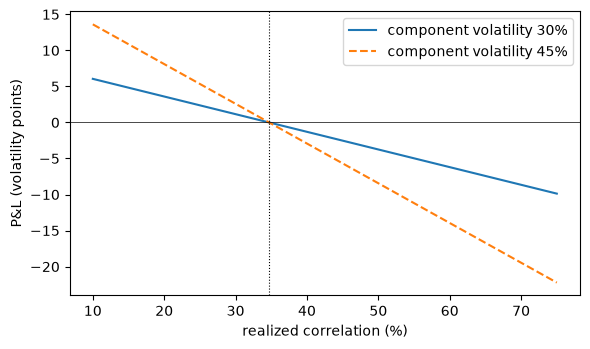

In [14]:
try:
    import matplotlib.pyplot as plt
    rhos = np.linspace(0.10, 0.75, 100)
    plt.figure(figsize=(6, 3.6))
    plt.plot(100 * rhos, [dispersion_pnl(30, r) for r in rhos], label="component volatility 30%")
    plt.plot(100 * rhos, [dispersion_pnl(45, r) for r in rhos], "--", label="component volatility 45%")
    plt.axhline(0, color="k", lw=0.5)
    plt.axvline(100 * rho_impl, color="k", ls=":", lw=0.8)
    plt.xlabel("realized correlation (%)")
    plt.ylabel("P&L (volatility points)")
    plt.legend()
    plt.tight_layout()
    plt.show()
except ImportError:
    pass

## 10. Forward variance — Example 22.9

Total variance to each date is $TK_{\text{var}}^2$; the variance over the second half
year is the difference, spread over the half year it covers.

In [15]:
fwd_var = (1.0 * 0.20**2 - 0.5 * 0.18**2) / 0.5
show("forward variance", fwd_var, 0.0476, tol=5e-5)
show("forward volatility (%)", 100 * sqrt(fwd_var), 21.82)
show("check: the two half-years average to the year", (0.18**2 + fwd_var) / 2, 0.0400, tol=5e-5)

forward variance                                       0.0476   book       0.0476   ok
forward volatility (%)                               21.81742   book        21.82   ok
check: the two half-years average to the year            0.04   book         0.04   ok


## What this notebook shows

* A variance swap is a strip of options weighted $1/K^2$. Its discrete error at
  ordinary volatility comes from where the grid meets the forward, not from the
  tails, and it shrinks with the square of the spacing.
* The variance strike sits above the volatility strike by an amount set by the
  volatility of volatility; a variance swap strike is not a volatility forecast.
* The hedged log contract earns realized variance path by path; the hedged straddle
  does not, because its gamma is concentrated near the strike.
* VIX is a rule. Changing which options count as quoted moves the index with no
  volatility changing.
* The inverse product's buying requirement grows as it loses money, and dispersion's
  loss is linear in correlation but scaled by component variance, which rises with it.

Every deterministic figure above reproduces the chapter; the simulation in Section 4
is illustrative, and its correlations depend on the seed only in the third decimal.